In [4]:
!pip install catboost lightgbm xgboost statsmodels

In [5]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

In [13]:
df = pd.read_csv("Iowa Liquor Sales (Jan 2021-Jan 2022).csv")

print("--- RAW DATA OVERVIEW ---")
print(f"Total Rows: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")
print("\nFirst 3 Rows:")
display(df.head(3))

--- RAW DATA OVERVIEW ---
Total Rows: 2,805,307
Total Columns: 24

First 3 Rows:


,invoice_and_item_number,date,store_number,store_name,address,city,zip_code,store_location,county_number,county,...,item_number,item_description,pack,bottle_volume_ml,state_bottle_cost,state_bottle_retail,bottles_sold,sale_dollars,volume_sold_liters,volume_sold_gallons
0,INV-33179700135,2021-01-04,2576,Hy-Vee Wine and Spirits / Storm Lake,1250 N Lake St,Storm Lake,50588.0,POINT (-95.200758 42.65318400000001),11.0,BUENA VIST,...,64870,Fireball Cinnamon Whiskey,48,100,0.90,1.35,48,64.80,4.8,1.26
1,INV-33196200106,2021-01-04,2649,Hy-Vee #3 / Dubuque,400 Locust St,Dubuque,52001.0,POINT (-90.666497 42.49721900000001),31.0,DUBUQUE,...,65200,Tequila Rose Liqueur,12,750,11.50,17.25,4,69.00,3.0,0.79
2,INV-33184300011,2021-01-04,2539,Hy-Vee Food Store / Iowa Falls,640 S. Oak,Iowa Falls,50126.0,POINT (-93.262364 42.508752),42.0,HARDIN,...,38008,Smirnoff 80prf PET,6,1750,14.75,22.13,6,132.78,10.5,2.77


In [14]:
cols_to_use = [
    "date",
    "item_description",
    "store_number",
    "state_bottle_cost",
    "state_bottle_retail",
    "bottles_sold",
    "sale_dollars",
    "volume_sold_liters",
]

df_clean = df[cols_to_use].dropna().copy()
df_clean["date"] = pd.to_datetime(df_clean["date"])
df_clean["bottles_sold"] = df_clean["bottles_sold"].astype(int)
df_clean["sale_dollars"] = df_clean["sale_dollars"].astype(float)
df_clean["state_bottle_cost"] = df_clean["state_bottle_cost"].astype(float)
df_clean["state_bottle_retail"] = df_clean["state_bottle_retail"].astype(
    float
)
df_clean["volume_sold_liters"] = df_clean["volume_sold_liters"].astype(float)

In [15]:
weekly_df = (
    df_clean.set_index("date")
    .resample("W")
    .agg(
        {
            "volume_sold_liters": "sum",
            "bottles_sold": "sum",
            "sale_dollars": "sum",
            "state_bottle_cost": "mean",
            "state_bottle_retail": "mean",
        }
    )
    .reset_index()
)
print("\n--- WEEKLY AGGREGATED DATA READY ---")
print(f"Total Weeks: {len(weekly_df)}")
display(weekly_df.head())


--- WEEKLY AGGREGATED DATA READY ---
Total Weeks: 57


,date,volume_sold_liters,bottles_sold,sale_dollars,state_bottle_cost,state_bottle_retail
0,2021-01-10,409901.79,532293,6990675.04,10.864065,16.292587
1,2021-01-17,434247.02,545439,7088747.25,10.920126,16.381434
2,2021-01-24,434980.43,559583,7218050.82,11.274929,16.913218
3,2021-01-31,445235.47,566066,7368186.75,11.005016,16.508933
4,2021-02-07,463118.80,567395,7323371.40,11.163707,16.745533


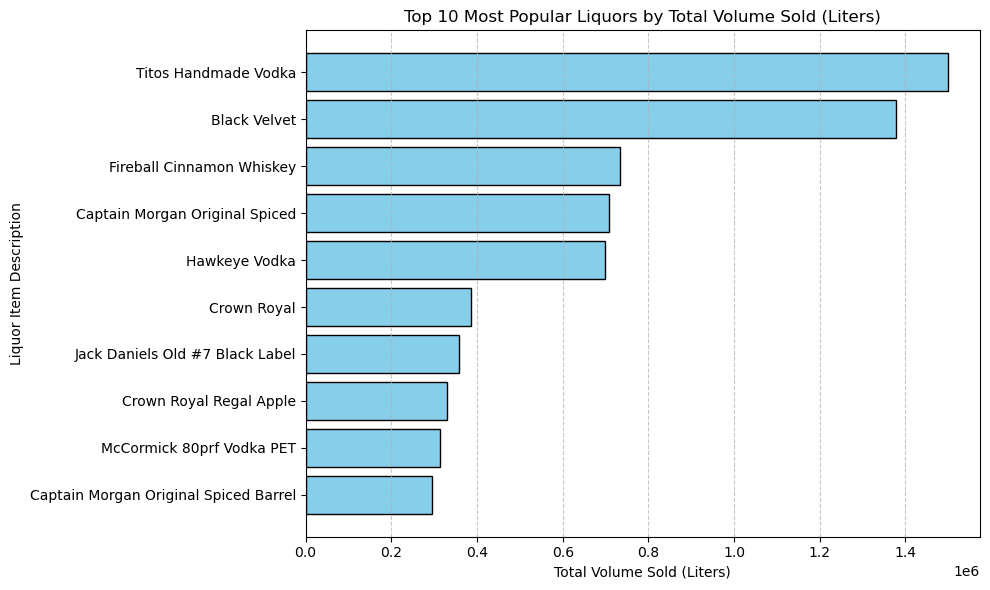

In [16]:
top_10_liquors = (
    df_clean.groupby("item_description")["volume_sold_liters"]
    .sum()
    .sort_values(ascending=True)
    .tail(10)
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_10_liquors.index,
    top_10_liquors.values,
    color="skyblue",
    edgecolor="black",
)
plt.title("Top 10 Most Popular Liquors by Total Volume Sold (Liters)")
plt.xlabel("Total Volume Sold (Liters)")
plt.ylabel("Liquor Item Description")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [8]:
weekly_df["volume_lag_1"] = weekly_df["volume_sold_liters"].shift(1)
weekly_df["volume_lag_2"] = weekly_df["volume_sold_liters"].shift(2)
weekly_df["volume_lag_3"] = weekly_df["volume_sold_liters"].shift(3)
weekly_df["volume_roll_mean_3"] = (
    weekly_df["volume_sold_liters"].shift(1).rolling(window=3).mean()
)

weekly_df["bottles_sold_lag_1"] = weekly_df["bottles_sold"].shift(1)
weekly_df["sale_dollars_lag_1"] = weekly_df["sale_dollars"].shift(1)

weekly_df["month"] = weekly_df["date"].dt.month
weekly_df["week_of_year"] = weekly_df["date"].dt.isocalendar().week.astype(int)

df_model = weekly_df.dropna().reset_index(drop=True)

In [9]:
target_col = "volume_sold_liters"
feature_cols = [
    "volume_lag_1",
    "volume_lag_2",
    "volume_lag_3",
    "volume_roll_mean_3",
    "bottles_sold_lag_1",
    "sale_dollars_lag_1",
    "state_bottle_cost",
    "state_bottle_retail",
    "month",
    "week_of_year",
]

X = df_model[feature_cols]
y = df_model[target_col]

split_idx = int(len(df_model) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

results = []
predictions_dict = {}

In [10]:
models = {
    "Linear Regression": (LinearRegression(), True),
    "Ridge Regression": (Ridge(alpha=1.0), True),
    "Lasso Regression": (Lasso(alpha=1.0), True),
    "Decision Tree": (DecisionTreeRegressor(random_state=42), False),
    "Random Forest": (
        RandomForestRegressor(n_estimators=100, random_state=42),
        False,
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(n_estimators=100, random_state=42),
        False,
    ),
    "XGBoost": (
        XGBRegressor(
            n_estimators=100, learning_rate=0.05, random_state=42, verbosity=0
        ),
        False,
    ),
    "LightGBM": (
        LGBMRegressor(
            n_estimators=100, learning_rate=0.05, random_state=42, verbose=-1
        ),
        False,
    ),
    "CatBoost": (
        CatBoostRegressor(
            iterations=100, learning_rate=0.05, random_seed=42, verbose=0
        ),
        False,
    ),
}

for name, (model, use_scaled) in models.items():
    X_tr = X_train_scaled if use_scaled else X_train
    X_te = X_test_scaled if use_scaled else X_test

    model.fit(X_tr, y_train)
    preds = model.predict(X_te)
    predictions_dict[name] = preds

    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)

    results.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2 Score": r2})

In [11]:
# 1. ARIMA
arima_model = ARIMA(y_train, order=(1, 1, 1)).fit()
arima_preds = arima_model.forecast(steps=len(y_test))
predictions_dict["ARIMA"] = arima_preds

results.append(
    {
        "Model": "ARIMA",
        "MAE": mean_absolute_error(y_test, arima_preds),
        "RMSE": np.sqrt(mean_squared_error(y_test, arima_preds)),
        "R2 Score": r2_score(y_test, arima_preds),
    }
)

# 2. SARIMA (with exogenous features)
sarima_model = SARIMAX(
    y_train,
    exog=X_train[["state_bottle_cost", "state_bottle_retail"]],
    order=(1, 1, 1),
    seasonal_order=(1, 0, 0, 12),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)

sarima_preds = sarima_model.forecast(
    steps=len(y_test),
    exog=X_test[["state_bottle_cost", "state_bottle_retail"]],
)
predictions_dict["SARIMA"] = sarima_preds

results.append(
    {
        "Model": "SARIMA",
        "MAE": mean_absolute_error(y_test, sarima_preds),
        "RMSE": np.sqrt(mean_squared_error(y_test, sarima_preds)),
        "R2 Score": r2_score(y_test, sarima_preds),
    }
)


--- ALL MODELS PERFORMANCE COMPARISON ---


,Model,MAE,RMSE,R2 Score
0,Ridge Regression,83797.167045,133965.928296,-0.035740
1,Gradient Boosting,90921.566879,133985.120322,-0.036037
2,Random Forest,90155.726655,134580.919675,-0.045271
3,Lasso Regression,85779.154507,134693.236103,-0.047017
4,Decision Tree,90403.733636,138075.685948,-0.100263
5,CatBoost,93133.028118,140165.383709,-0.133818
6,LightGBM,93064.829690,141889.168807,-0.161878
7,Linear Regression,92672.357098,142223.507793,-0.167360
8,XGBoost,96033.386250,145086.651321,-0.214834
9,ARIMA,126791.962599,172090.709216,-0.709137


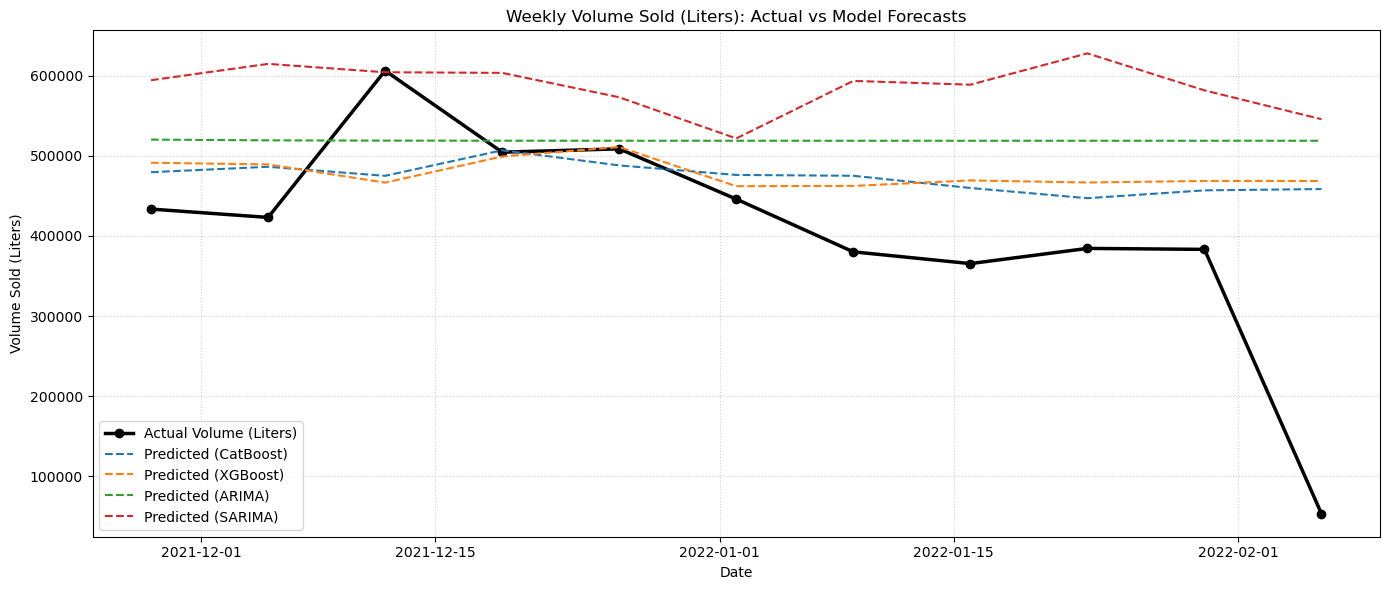

In [12]:
results_df = (
    pd.DataFrame(results).sort_values(by="RMSE").reset_index(drop=True)
)
print("\n--- ALL MODELS PERFORMANCE COMPARISON ---")
display(results_df)

# Plot Forecast Comparison
plt.figure(figsize=(14, 6))
test_dates = df_model["date"].iloc[split_idx:]

plt.plot(
    test_dates,
    y_test.values,
    label="Actual Volume (Liters)",
    color="black",
    linewidth=2.5,
    marker="o",
)

for name in ["CatBoost", "XGBoost", "ARIMA", "SARIMA"]:
    plt.plot(
        test_dates,
        predictions_dict[name],
        label=f"Predicted ({name})",
        linestyle="--",
    )

plt.title("Weekly Volume Sold (Liters): Actual vs Model Forecasts")
plt.xlabel("Date")
plt.ylabel("Volume Sold (Liters)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()